In [14]:
from huggingface_hub import hf_hub_download
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw/ai_energy_score")
DATA_DIR.mkdir(parents=True, exist_ok=True)

tasks = [
    "text_generation",
    "summarization",
    "question_answering"
]

datasets = {}

for task in tasks:

    file_path = hf_hub_download(
        repo_id="AIEnergyScore/Leaderboard",
        repo_type="space",
        filename=f"data/energy/{task}.csv"
    )

    df = pd.read_csv(file_path)

    datasets[task] = df

    df.to_csv(
        DATA_DIR / f"{task}.csv",
        index=False
    )

    print(f"{task}: {df.shape}")

text_generation: (62, 5)
summarization: (11, 3)
question_answering: (18, 3)


In [2]:
df = datasets["text_generation"]

df.head()

,model,total_gpu_energy,energy_score,class,test date
0,berkeley-nest/Starling-LM-7B-alpha,0.019011,2,A,Feb 25
1,distilbert/distilgpt2,0.001313,5,A,Feb 25
2,Salesforce/xLAM-7b-r,0.019170,2,A,Feb 25
3,openai-community/gpt2,0.002146,5,A,Feb 25
4,openai-community/gpt2-xl,0.008921,4,A,Feb 25


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   model             62 non-null     object 
 1   total_gpu_energy  62 non-null     float64
 2   energy_score      62 non-null     int64  
 3   class             62 non-null     object 
 4   test date         62 non-null     object 
dtypes: float64(1), int64(1), object(3)
memory usage: 2.6+ KB


In [4]:
df.columns.tolist()

['model', 'total_gpu_energy', 'energy_score', 'class', 'test date']

In [5]:
# Nombre de lignes et de colonnes
print("Shape:", df.shape)

# Valeurs manquantes
print("\nMissing values:")
print(df.isnull().sum())

# Doublons
print("\nDuplicates:")
print(df.duplicated().sum())

# Statistiques descriptives
df.describe(include="all")

Shape: (62, 5)

Missing values:
model               0
total_gpu_energy    0
energy_score        0
class               0
test date           0
dtype: int64

Duplicates:
0


,model,total_gpu_energy,energy_score,class,test date
count,62,62.000000,62.000000,62,62
unique,62,NaN,NaN,3,2
top,berkeley-nest/Starling-LM-7B-alpha,NaN,NaN,A,Feb 25
freq,1,NaN,NaN,44,40
mean,NaN,0.253875,3.645161,NaN,NaN
std,NaN,0.627816,1.472110,NaN,NaN
min,NaN,0.001313,1.000000,NaN,NaN
25%,NaN,0.008740,2.000000,NaN,NaN
50%,NaN,0.018770,4.000000,NaN,NaN
75%,NaN,0.050190,5.000000,NaN,NaN


In [6]:
df["energy_wh_per_1k"] = (
    pd.to_numeric(
        df["total_gpu_energy"],
        errors="coerce"
    ) * 1000
)

df[
    ["model", "energy_wh_per_1k"]
].sort_values(
    "energy_wh_per_1k"
).head(10)

,model,energy_wh_per_1k
1,distilbert/distilgpt2,1.313
16,facebook/opt-125m,1.944
3,openai-community/gpt2,2.146
7,openai-community/openai-gpt,2.704
5,openai-community/gpt2-medium,3.956
43,tencent/Hunyuan-1.8B-Instruct,4.200
14,allenai/OLMo-1B-hf,5.594
6,openai-community/gpt2-large,6.121
9,microsoft/phi-1_5,6.290
8,microsoft/phi-1,6.393


Matplotlib is building the font cache; this may take a moment.


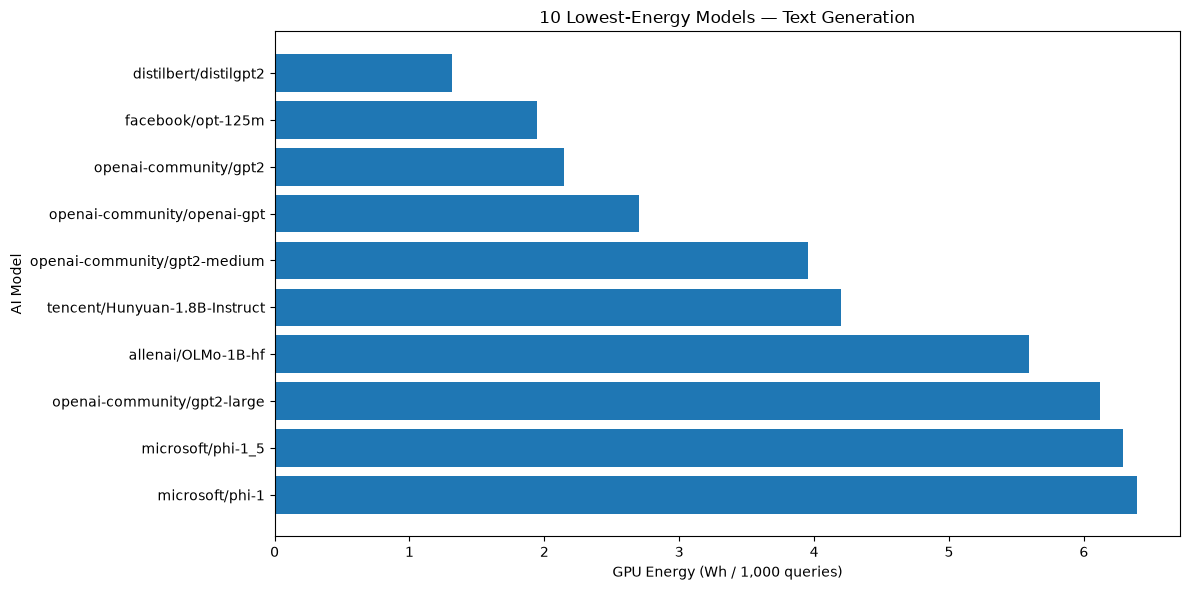

In [7]:
import matplotlib.pyplot as plt

top10 = (
    df.dropna(subset=["energy_wh_per_1k"])
      .sort_values("energy_wh_per_1k")
      .head(10)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top10["model"],
    top10["energy_wh_per_1k"]
)

plt.xlabel("GPU Energy (Wh / 1,000 queries)")
plt.ylabel("AI Model")
plt.title("10 Lowest-Energy Models — Text Generation")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [8]:
for task, df_task in datasets.items():
    print(f"\nTask: {task}")
    print(f"Number of models: {df_task['model'].nunique()}")
    print(f"Number of rows: {len(df_task)}")
    print(f"Columns: {df_task.columns.tolist()}")


Task: text_generation
Number of models: 62
Number of rows: 62
Columns: ['model', 'total_gpu_energy', 'energy_score', 'class', 'test date', 'energy_wh_per_1k']

Task: summarization
Number of models: 11
Number of rows: 11
Columns: ['model', 'total_gpu_energy', 'energy_score']

Task: question_answering
Number of models: 18
Number of rows: 18
Columns: ['model', 'total_gpu_energy', 'energy_score']


In [9]:
models_by_task = {
    task: set(df_task["model"])
    for task, df_task in datasets.items()
}

common_models = set.intersection(
    *models_by_task.values()
)

print("Models available in all tasks:", len(common_models))

print("\nCommon models:")
for model in sorted(common_models):
    print(model)

Models available in all tasks: 0

Common models:


In [10]:
df = datasets["text_generation"].copy()

df["energy_wh_per_1k"] = (
    df["total_gpu_energy"] * 1000
)

df["energy_wh_per_1k"].describe()

count      62.000000
mean      253.874673
std       627.816009
min         1.313000
25%         8.740250
50%        18.769500
75%        50.190000
max      3426.382000
Name: energy_wh_per_1k, dtype: float64

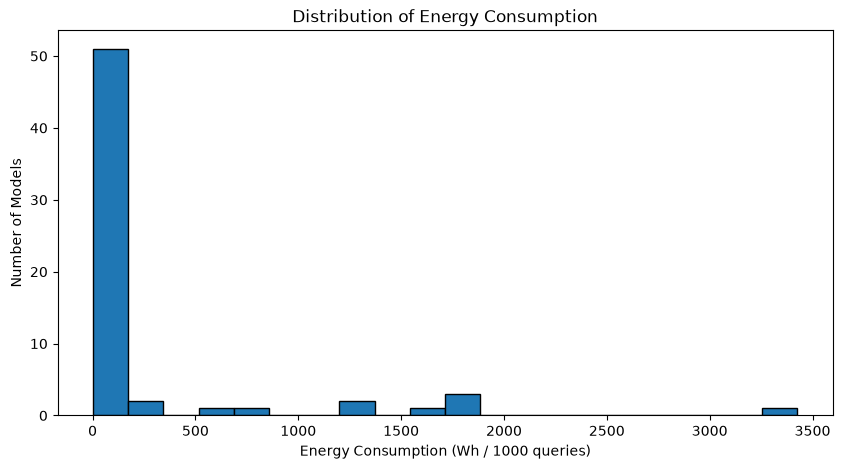

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["energy_wh_per_1k"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.xlabel("Energy Consumption (Wh / 1000 queries)")
plt.ylabel("Number of Models")
plt.title("Distribution of Energy Consumption")

plt.show()

In [12]:
from itertools import combinations

models_by_task = {
    task: set(df_task["model"])
    for task, df_task in datasets.items()
}

for task1, task2 in combinations(models_by_task, 2):

    common = models_by_task[task1] & models_by_task[task2]

    print(f"\n{task1} vs {task2}")
    print(f"Common models: {len(common)}")

    for model in sorted(common):
        print(" -", model)


text_generation vs summarization
Common models: 0

text_generation vs question_answering
Common models: 0

summarization vs question_answering
Common models: 5
 - google-t5/t5-11b
 - google-t5/t5-3b
 - google-t5/t5-base
 - google-t5/t5-large
 - google-t5/t5-small


In [14]:
for model in sorted(
    datasets["text_generation"]["model"].unique()
):
    print(model)

01-ai/Yi-1.5-34B
01-ai/Yi-1.5-9B
CohereForAI/aya-23-8B
CohereForAI/c4ai-command-r-plus
HuggingFaceTB/SmolLM-1.7B
HuggingFaceTB/SmolLM-135M
HuggingFaceTB/SmolLM-360M
HuggingFaceTB/SmolLM2-1.7B-Instruct
HuggingFaceTB/SmolLM3-3B
LGAI-EXAONE/EXAONE-4.0-32B
Qwen/QwQ-32B-Preview
Qwen/Qwen2.5-72B-Instruct
Qwen/Qwen2.5-Coder-14B
Qwen/Qwen3-0.6B
Qwen/Qwen3-235B-A22B
Qwen/Qwen3-30B-A3B
Salesforce/xLAM-7b-r
allenai/OLMo-1.7-7B-hf
allenai/OLMo-1B-hf
berkeley-nest/Starling-LM-7B-alpha
crm-sf/TextBase-70B
deepseek-ai/DeepSeek-R1-Distill-Llama-70B
deepseek-ai/DeepSeek-R1-Distill-Qwen-32B
distilbert/distilgpt2
facebook/opt-125m
facebook/opt-2.7b
google/gemma-2-2b-it
google/gemma-2b
google/gemma-3-1b-pt
google/gemma-3-270m
google/gemma-3-27b-pt
google/gemma-3-4b-pt
google/gemma-7b
ibm-granite/*granite-4.0-h-tiny
ibm-granite/granite-4.0-micro
meta-llama/Llama-2-13b-hf
meta-llama/Llama-2-70b-hf
meta-llama/Llama-2-7b-hf
meta-llama/Meta-Llama-3-70B
meta-llama/Meta-Llama-3-8B
meta-llama/Meta-Llama-3.1-8B
mi

In [15]:
import pandas as pd

all_data = []

for task, df_task in datasets.items():

    temp = df_task.copy()

    temp["task"] = task

    temp["energy_wh_per_1k"] = (
        pd.to_numeric(
            temp["total_gpu_energy"],
            errors="coerce"
        ) * 1000
    )

    all_data.append(temp)

energy_df = pd.concat(
    all_data,
    ignore_index=True
)

energy_df = energy_df.rename(
    columns={
        "total_gpu_energy": "energy_wh_per_query",
        "energy_score": "energy_rating",
        "class": "energy_class",
        "test date": "test_date"
    }
)

energy_df.head()

,model,energy_wh_per_query,energy_rating,energy_class,test_date,task,energy_wh_per_1k
0,berkeley-nest/Starling-LM-7B-alpha,0.019011,2,A,Feb 25,text_generation,19.011
1,distilbert/distilgpt2,0.001313,5,A,Feb 25,text_generation,1.313
2,Salesforce/xLAM-7b-r,0.019170,2,A,Feb 25,text_generation,19.170
3,openai-community/gpt2,0.002146,5,A,Feb 25,text_generation,2.146
4,openai-community/gpt2-xl,0.008921,4,A,Feb 25,text_generation,8.921


In [16]:
energy_df.groupby("task").agg(
    models=("model", "nunique"),
    min_energy=("energy_wh_per_1k", "min"),
    median_energy=("energy_wh_per_1k", "median"),
    max_energy=("energy_wh_per_1k", "max")
).round(3)

,models,min_energy,median_energy,max_energy
task,,,,
question_answering,18,0.055,0.992,178.130
summarization,11,0.785,3.524,34.807
text_generation,62,1.313,18.770,3426.382


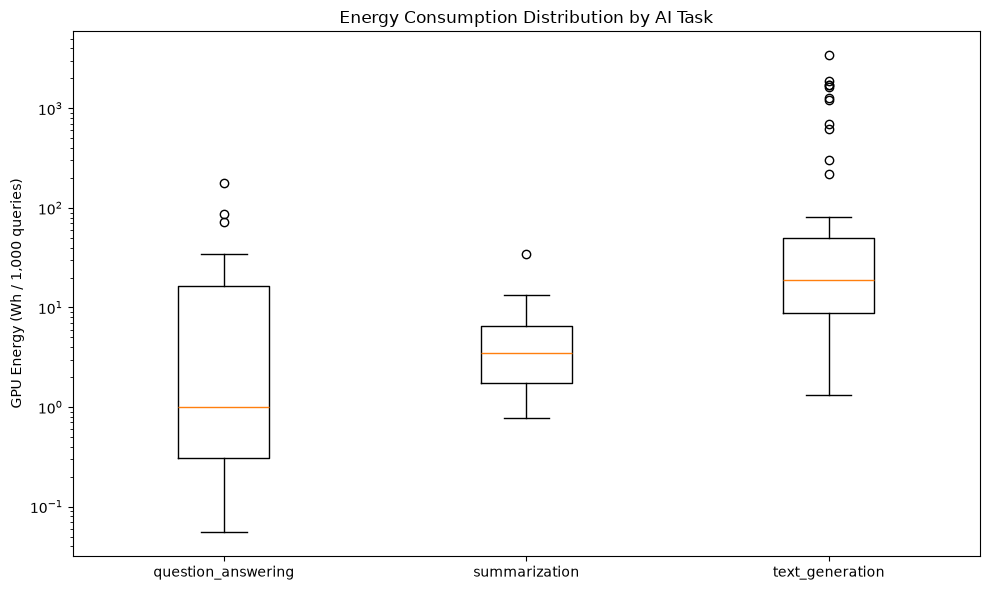

In [17]:
import matplotlib.pyplot as plt

tasks = [
    "question_answering",
    "summarization",
    "text_generation"
]

data = [
    energy_df.loc[
        (energy_df["task"] == task)
        & (energy_df["energy_wh_per_1k"] > 0),
        "energy_wh_per_1k"
    ].dropna()
    for task in tasks
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    data,
    tick_labels=tasks,
    showfliers=True
)

ax.set_yscale("log")

ax.set_ylabel("GPU Energy (Wh / 1,000 queries)")
ax.set_title("Energy Consumption Distribution by AI Task")

plt.tight_layout()
plt.show()

In [18]:
energy_df.loc[
    energy_df.groupby("task")["energy_wh_per_1k"].idxmax(),
    ["model", "task", "energy_wh_per_1k"]
]

,model,task,energy_wh_per_1k
87,google-t5/t5-11b,question_answering,178.130109
69,google-t5/t5-11b,summarization,34.807171
35,CohereForAI/c4ai-command-r-plus,text_generation,3426.382000


In [19]:
energy_df.loc[
    energy_df.groupby("task")["energy_wh_per_1k"].idxmin(),
    ["model", "task", "energy_wh_per_1k"]
]

,model,task,energy_wh_per_1k
79,mrm8488/bert-tiny-finetuned-squadv2,question_answering,0.055400
64,KipperDev/bart_summarizer_model,summarization,0.784852
1,distilbert/distilgpt2,text_generation,1.313000


In [10]:
from datasets import load_dataset

quality_dataset = load_dataset(
    "open-llm-leaderboard/contents",
    split="train"
)

quality_df = quality_dataset.to_pandas()

print("Shape:", quality_df.shape)
print(quality_df.columns.tolist())

README.md:   0%|          | 0.00/1.63k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4576 [00:00<?, ? examples/s]

Shape: (4576, 36)
['eval_name', 'Precision', 'Type', 'T', 'Weight type', 'Architecture', 'Model', 'fullname', 'Model sha', 'Average ⬆️', 'Hub License', 'Hub ❤️', '#Params (B)', 'Available on the hub', 'MoE', 'Flagged', 'Chat Template', 'CO₂ cost (kg)', 'IFEval Raw', 'IFEval', 'BBH Raw', 'BBH', 'MATH Lvl 5 Raw', 'MATH Lvl 5', 'GPQA Raw', 'GPQA', 'MUSR Raw', 'MUSR', 'MMLU-PRO Raw', 'MMLU-PRO', 'Merged', 'Official Providers', 'Upload To Hub Date', 'Submission Date', 'Generation', 'Base Model']


In [11]:
quality_df[
    [
        "fullname",
        "Average ⬆️",
        "MMLU-PRO",
        "IFEval",
        "#Params (B)"
    ]
].head(10)

,fullname,Average ⬆️,MMLU-PRO,IFEval,#Params (B)
0,0-hero/Matter-0.2-7B-DPO,8.906361,1.817376,33.027921,7.242
1,01-ai/Yi-1.5-34B,25.646494,40.732122,28.411725,34.389
2,01-ai/Yi-1.5-34B-32K,26.727913,41.212323,31.186917,34.389
3,01-ai/Yi-1.5-34B-Chat,33.357994,39.116061,60.667584,34.389
4,01-ai/Yi-1.5-34B-Chat-16K,29.403555,39.383865,45.645000,34.389
5,01-ai/Yi-1.5-6B,16.745698,23.823508,26.166017,6.061
6,01-ai/Yi-1.5-6B-Chat,22.784006,24.368351,51.452701,6.061
7,01-ai/Yi-1.5-9B,22.153902,32.402482,29.358436,8.829
8,01-ai/Yi-1.5-9B-32K,19.809786,30.721779,23.031113,8.829
9,01-ai/Yi-1.5-9B-Chat,29.530872,33.058141,60.455259,8.829


In [16]:
energy_models = set(
    energy_df.loc[
        energy_df["task"] == "text_generation",
        "model"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

quality_models = set(
    quality_df["fullname"]
    .astype(str)
    .str.strip()
    .str.lower()
)

common_models = energy_models.intersection(quality_models)

print("Energy models:", len(energy_models))
print("Quality models:", len(quality_models))
print("Common models:", len(common_models))

for model in sorted(common_models):
    print(model)

Energy models: 62
Quality models: 4495
Common models: 38
01-ai/yi-1.5-34b
01-ai/yi-1.5-9b
allenai/olmo-1.7-7b-hf
allenai/olmo-1b-hf
berkeley-nest/starling-lm-7b-alpha
cohereforai/aya-23-8b
cohereforai/c4ai-command-r-plus
deepseek-ai/deepseek-r1-distill-llama-70b
deepseek-ai/deepseek-r1-distill-qwen-32b
distilbert/distilgpt2
google/gemma-2-2b-it
google/gemma-2b
google/gemma-7b
huggingfacetb/smollm-1.7b
huggingfacetb/smollm-135m
huggingfacetb/smollm-360m
huggingfacetb/smollm2-1.7b-instruct
meta-llama/llama-2-13b-hf
meta-llama/llama-2-70b-hf
meta-llama/llama-2-7b-hf
meta-llama/meta-llama-3-70b
meta-llama/meta-llama-3-8b
microsoft/phi-1
microsoft/phi-1_5
microsoft/phi-2
microsoft/phi-4
mistralai/ministral-8b-instruct-2410
mistralai/mistral-7b-v0.1
mistralai/mistral-nemo-instruct-2407
mistralai/mixtral-8x7b-v0.1
openai-community/gpt2
openai-community/gpt2-large
openai-community/gpt2-medium
openai-community/gpt2-xl
qwen/qwen2.5-72b-instruct
qwen/qwen2.5-coder-14b
qwen/qwq-32b-preview
tiiuae/

In [ ]:
energy_text = datasets["text_generation"].copy()

energy_text["model_key"] = (
    energy_text["model"]
    .astype(str)
    .str.strip()
    .str.lower()
)

quality_df["model_key"] = (
    quality_df["fullname"]
    .astype(str)
    .str.strip()
    .str.lower()
)

quality_cols = [
    "model_key",
    "Average ⬆️",
    "MMLU-PRO",
    "IFEval",
    "#Params (B)"
]

matched_df = energy_text.merge(
    quality_df[quality_cols],
    on="model_key",
    how="inner",
    validate="one_to_many"
)

matched_df[
    [
        "model",
        "energy_wh_per_1k",
        "Average ⬆️",
        "MMLU-PRO",
        "IFEval"
    ]
].head(10)

In [17]:
energy_text = energy_df[
    energy_df["task"] == "text_generation"
].copy()

energy_text["model_key"] = (
    energy_text["model"]
    .astype(str)
    .str.strip()
    .str.lower()
)

energy_text = energy_text[
    ["model", "model_key", "energy_wh_per_1k"]
]

energy_text.head()

,model,model_key,energy_wh_per_1k
0,berkeley-nest/Starling-LM-7B-alpha,berkeley-nest/starling-lm-7b-alpha,19.011
1,distilbert/distilgpt2,distilbert/distilgpt2,1.313
2,Salesforce/xLAM-7b-r,salesforce/xlam-7b-r,19.170
3,openai-community/gpt2,openai-community/gpt2,2.146
4,openai-community/gpt2-xl,openai-community/gpt2-xl,8.921


In [18]:
quality = quality_df.copy()

quality["model_key"] = (
    quality["fullname"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(quality.columns.tolist())

['eval_name', 'Precision', 'Type', 'T', 'Weight type', 'Architecture', 'Model', 'fullname', 'Model sha', 'Average ⬆️', 'Hub License', 'Hub ❤️', '#Params (B)', 'Available on the hub', 'MoE', 'Flagged', 'Chat Template', 'CO₂ cost (kg)', 'IFEval Raw', 'IFEval', 'BBH Raw', 'BBH', 'MATH Lvl 5 Raw', 'MATH Lvl 5', 'GPQA Raw', 'GPQA', 'MUSR Raw', 'MUSR', 'MMLU-PRO Raw', 'MMLU-PRO', 'Merged', 'Official Providers', 'Upload To Hub Date', 'Submission Date', 'Generation', 'Base Model', 'model_key']


In [ ]:
from datasets import load_dataset

quality_dataset = load_dataset(
    "open-llm-leaderboard/contents",
    split="train"
)

quality_df = quality_dataset.to_pandas()

print("Shape:", quality_df.shape)
print(quality_df.columns.tolist())

README.md:   0%|          | 0.00/1.63k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4576 [00:00<?, ? examples/s]

Shape: (4576, 36)
['eval_name', 'Precision', 'Type', 'T', 'Weight type', 'Architecture', 'Model', 'fullname', 'Model sha', 'Average ⬆️', 'Hub License', 'Hub ❤️', '#Params (B)', 'Available on the hub', 'MoE', 'Flagged', 'Chat Template', 'CO₂ cost (kg)', 'IFEval Raw', 'IFEval', 'BBH Raw', 'BBH', 'MATH Lvl 5 Raw', 'MATH Lvl 5', 'GPQA Raw', 'GPQA', 'MUSR Raw', 'MUSR', 'MMLU-PRO Raw', 'MMLU-PRO', 'Merged', 'Official Providers', 'Upload To Hub Date', 'Submission Date', 'Generation', 'Base Model']


In [19]:
duplicates = (
    quality.groupby("model_key")
    .size()
    .sort_values(ascending=False)
)

print("Models with multiple evaluations:")
print((duplicates > 1).sum())

print("\nExamples:")
print(duplicates.head(10))

Models with multiple evaluations:
81

Examples:
model_key
spow12/chatwaifu_v2.0_22b                 2
qingy2019/oracle-14b                      2
allenai/llama-3.1-tulu-3-8b               2
replete-ai/replete-llm-qwen2-7b           2
nazimali/mistral-nemo-kurdish-instruct    2
allenai/llama-3.1-tulu-3-70b              2
arcee-ai/arcee-spark                      2
akjindal53244/llama-3.1-storm-8b          2
meta-llama/meta-llama-3-8b-instruct       2
recoilme/recoilme-gemma-2-9b-v0.2         2
dtype: int64


In [20]:
matched_df = energy_text.merge(
    quality,
    on="model_key",
    how="inner",
    validate="one_to_many"
)

print("Matched rows:", len(matched_df))
print("Unique models:", matched_df["model_key"].nunique())

matched_df.head()

Matched rows: 41
Unique models: 38


,model,model_key,energy_wh_per_1k,eval_name,Precision,Type,T,Weight type,Architecture,Model,...,MUSR Raw,MUSR,MMLU-PRO Raw,MMLU-PRO,Merged,Official Providers,Upload To Hub Date,Submission Date,Generation,Base Model
0,berkeley-nest/Starling-LM-7B-alpha,berkeley-nest/starling-lm-7b-alpha,19.011,berkeley-nest_Starling-LM-7B-alpha_bfloat16,bfloat16,"💬 chat models (RLHF, DPO, IFT, ...)",💬,Original,MistralForCausalLM,"<a target=""_blank"" href=""https://huggingface.c...",...,0.412010,9.501302,0.317154,24.128251,False,True,2023-11-25,2024-06-12,0,berkeley-nest/Starling-LM-7B-alpha
1,distilbert/distilgpt2,distilbert/distilgpt2,1.313,distilbert_distilgpt2_bfloat16,bfloat16,🟢 pretrained,🟢,Original,GPT2LMHeadModel,"<a target=""_blank"" href=""https://huggingface.c...",...,0.420729,11.157813,0.118684,2.075946,False,True,2022-03-02,2024-06-12,0,distilbert/distilgpt2
2,openai-community/gpt2,openai-community/gpt2,2.146,openai-community_gpt2_bfloat16,bfloat16,🟢 pretrained,🟢,Original,GPT2LMHeadModel,"<a target=""_blank"" href=""https://huggingface.c...",...,0.447052,15.348177,0.115941,1.771203,False,True,2022-03-02,2024-06-12,0,openai-community/gpt2
3,openai-community/gpt2,openai-community/gpt2,2.146,openai-community_gpt2_float16,float16,🟢 pretrained,🟢,Original,GPT2LMHeadModel,"<a target=""_blank"" href=""https://huggingface.c...",...,0.439021,13.910938,0.116523,1.835845,False,True,2022-03-02,2024-08-12,0,openai-community/gpt2
4,openai-community/gpt2-xl,openai-community/gpt2-xl,8.921,openai-community_gpt2-xl_bfloat16,bfloat16,🟢 pretrained,🟢,Original,GPT2LMHeadModel,"<a target=""_blank"" href=""https://huggingface.c...",...,0.370958,4.036458,0.113115,1.457225,False,True,2022-03-02,2024-06-12,0,openai-community/gpt2-xl


In [21]:
score_columns = [
    "Average ⬆️",
    "MMLU-PRO",
    "IFEval",
    "#Params (B)"
]

for col in score_columns:
    if col in matched_df.columns:
        print(
            col,
            "— non-null:",
            matched_df[col].notna().sum(),
            "/",
            len(matched_df)
        )
    else:
        print(col, "— column not found")

Average ⬆️ — non-null: 41 / 41
MMLU-PRO — non-null: 41 / 41
IFEval — non-null: 41 / 41
#Params (B) — non-null: 41 / 41


In [22]:
available_columns = [
    col for col in [
        "model",
        "energy_wh_per_1k",
        "Average ⬆️",
        "MMLU-PRO",
        "IFEval",
        "#Params (B)"
    ]
    if col in matched_df.columns
]

matched_df[available_columns].head(15)

,model,energy_wh_per_1k,Average ⬆️,MMLU-PRO,IFEval,#Params (B)
0,berkeley-nest/Starling-LM-7B-alpha,19.011,20.839361,24.128251,54.804918,7.242
1,distilbert/distilgpt2,1.313,4.002274,2.075946,6.110010,0.088
2,openai-community/gpt2,2.146,6.510807,1.771203,17.925327,0.137
3,openai-community/gpt2,2.146,6.334235,1.835845,17.795449,0.137
4,openai-community/gpt2-xl,8.921,5.093481,1.457225,20.385799,1.608
5,openai-community/gpt2-medium,3.956,5.902340,2.020538,22.084403,0.380
6,openai-community/gpt2-large,6.121,5.567707,1.577275,20.478220,0.812
7,microsoft/phi-1,6.393,5.574318,1.798907,20.680572,1.418
8,microsoft/phi-1_5,6.290,7.170967,7.681368,20.328395,1.418
9,microsoft/phi-2,9.864,15.534292,18.088800,27.387554,2.780


In [23]:
duplicated_models = matched_df[
    matched_df.duplicated(
        subset=["model_key"],
        keep=False
    )
].sort_values("model_key")

display(
    duplicated_models[
        [
            "model",
            "energy_wh_per_1k",
            "Average ⬆️",
            "MMLU-PRO",
            "IFEval",
            "#Params (B)"
        ]
    ]
)

,model,energy_wh_per_1k,Average ⬆️,MMLU-PRO,IFEval,#Params (B)
10,microsoft/phi-4,28.741,29.483417,47.722739,4.878500,14.660
11,microsoft/phi-4,28.741,30.358128,47.630393,5.852693,14.660
29,mistralai/Mixtral-8x7B-v0.1,615.390,19.565281,31.663712,24.152693,46.703
30,mistralai/Mixtral-8x7B-v0.1,615.390,19.665109,31.903812,23.260948,46.703
2,openai-community/gpt2,2.146,6.510807,1.771203,17.925327,0.137
3,openai-community/gpt2,2.146,6.334235,1.835845,17.795449,0.137


In [24]:
print(matched_df.columns.tolist())

['model', 'model_key', 'energy_wh_per_1k', 'eval_name', 'Precision', 'Type', 'T', 'Weight type', 'Architecture', 'Model', 'fullname', 'Model sha', 'Average ⬆️', 'Hub License', 'Hub ❤️', '#Params (B)', 'Available on the hub', 'MoE', 'Flagged', 'Chat Template', 'CO₂ cost (kg)', 'IFEval Raw', 'IFEval', 'BBH Raw', 'BBH', 'MATH Lvl 5 Raw', 'MATH Lvl 5', 'GPQA Raw', 'GPQA', 'MUSR Raw', 'MUSR', 'MMLU-PRO Raw', 'MMLU-PRO', 'Merged', 'Official Providers', 'Upload To Hub Date', 'Submission Date', 'Generation', 'Base Model']


In [25]:
duplicated_models.T

,10,11,29,30,2,3
model,microsoft/phi-4,microsoft/phi-4,mistralai/Mixtral-8x7B-v0.1,mistralai/Mixtral-8x7B-v0.1,openai-community/gpt2,openai-community/gpt2
model_key,microsoft/phi-4,microsoft/phi-4,mistralai/mixtral-8x7b-v0.1,mistralai/mixtral-8x7b-v0.1,openai-community/gpt2,openai-community/gpt2
energy_wh_per_1k,28.741,28.741,615.39,615.39,2.146,2.146
eval_name,microsoft_phi-4_float16,microsoft_phi-4_bfloat16,mistralai_Mixtral-8x7B-v0.1_bfloat16,mistralai_Mixtral-8x7B-v0.1_float16,openai-community_gpt2_bfloat16,openai-community_gpt2_float16
Precision,float16,bfloat16,bfloat16,float16,bfloat16,float16
Type,🟢 pretrained,"💬 chat models (RLHF, DPO, IFT, ...)",🟢 pretrained,🔶 fine-tuned on domain-specific datasets,🟢 pretrained,🟢 pretrained
T,🟢,💬,🟢,🔶,🟢,🟢
Weight type,Original,Original,Original,Original,Original,Original
Architecture,Phi3ForCausalLM,Phi3ForCausalLM,MixtralForCausalLM,MixtralForCausalLM,GPT2LMHeadModel,GPT2LMHeadModel
Model,"<a target=""_blank"" href=""https://huggingface.c...","<a target=""_blank"" href=""https://huggingface.c...","<a target=""_blank"" href=""https://huggingface.c...","<a target=""_blank"" href=""https://huggingface.c...","<a target=""_blank"" href=""https://huggingface.c...","<a target=""_blank"" href=""https://huggingface.c..."


In [26]:
cols = [
    "model",
    "eval_name",
    "Model sha",
    "Submission Date",
    "Precision",
    "Weight type",
    "Chat Template",
    "MMLU-PRO",
    "IFEval"
]

display(
    duplicated_models[cols]
    .sort_values(["model", "Submission Date"])
)

,model,eval_name,Model sha,Submission Date,Precision,Weight type,Chat Template,MMLU-PRO,IFEval
10,microsoft/phi-4,microsoft_phi-4_float16,381727a5ee103da6c1b14ecd3d39cd09832cbcf8,2025-01-08,float16,Original,False,47.722739,4.878500
11,microsoft/phi-4,microsoft_phi-4_bfloat16,381727a5ee103da6c1b14ecd3d39cd09832cbcf8,2025-01-08,bfloat16,Original,True,47.630393,5.852693
30,mistralai/Mixtral-8x7B-v0.1,mistralai_Mixtral-8x7B-v0.1_float16,985aa055896a8f943d4a9f2572e6ea1341823841,2024-06-27,float16,Original,False,31.903812,23.260948
29,mistralai/Mixtral-8x7B-v0.1,mistralai_Mixtral-8x7B-v0.1_bfloat16,985aa055896a8f943d4a9f2572e6ea1341823841,2024-08-20,bfloat16,Original,False,31.663712,24.152693
2,openai-community/gpt2,openai-community_gpt2_bfloat16,607a30d783dfa663caf39e06633721c8d4cfcd7e,2024-06-12,bfloat16,Original,False,1.771203,17.925327
3,openai-community/gpt2,openai-community_gpt2_float16,607a30d783dfa663caf39e06633721c8d4cfcd7e,2024-08-12,float16,Original,False,1.835845,17.795449


In [27]:
import pandas as pd

clean_df = matched_df.copy()

# Convertir les dates
clean_df["Submission Date"] = pd.to_datetime(
    clean_df["Submission Date"],
    errors="coerce"
)

# Définir la priorité des précisions
precision_priority = {
    "float16": 0,
    "bfloat16": 1
}

clean_df["precision_priority"] = (
    clean_df["Precision"]
    .astype(str)
    .str.lower()
    .map(precision_priority)
    .fillna(2)
)

# Trier les évaluations
clean_df = clean_df.sort_values(
    by=[
        "model_key",
        "precision_priority",
        "Submission Date"
    ],
    ascending=[
        True,
        True,
        False
    ]
)

# Conserver une évaluation par modèle
clean_df = clean_df.drop_duplicates(
    subset="model_key",
    keep="first"
)

print("Nombre de modèles :", len(clean_df))

Nombre de modèles : 38


In [28]:
final_df = clean_df[
    [
        "model",
        "model_key",
        "energy_wh_per_1k",
        "Average ⬆️",
        "MMLU-PRO",
        "IFEval",
        "#Params (B)",
        "Precision",
        "Model sha",
        "Submission Date"
    ]
].copy()

final_df = final_df.rename(
    columns={
        "Average ⬆️": "average_score",
        "MMLU-PRO": "mmlu_pro_score",
        "IFEval": "ifeval_score",
        "#Params (B)": "parameters_b",
        "Precision": "precision",
        "Model sha": "model_sha",
        "Submission Date": "submission_date"
    }
)

display(final_df.head())

,model,model_key,energy_wh_per_1k,average_score,mmlu_pro_score,ifeval_score,parameters_b,precision,model_sha,submission_date
32,01-ai/Yi-1.5-34B,01-ai/yi-1.5-34b,56.079,25.646494,40.732122,28.411725,34.389,bfloat16,4b486f81c935a2dadde84c6baa1e1370d40a098f,2024-06-12
28,01-ai/Yi-1.5-9B,01-ai/yi-1.5-9b,23.001,22.153902,32.402482,29.358436,8.829,bfloat16,8cfde9604384c50137bee480b8cef8a08e5ae81d,2024-06-12
13,allenai/OLMo-1.7-7B-hf,allenai/olmo-1.7-7b-hf,16.831,3.800232,1.374113,15.689703,0.000,float16,a2a514275cb69a5f9b3dd51e0a4e92df88a12dfb,NaT
14,allenai/OLMo-1B-hf,allenai/olmo-1b-hf,5.594,6.633924,1.928191,21.819661,1.177,bfloat16,8e995430edd24416ccfa98b5b283fa07b0c9f1a9,2024-06-12
0,berkeley-nest/Starling-LM-7B-alpha,berkeley-nest/starling-lm-7b-alpha,19.011,20.839361,24.128251,54.804918,7.242,bfloat16,1dddf3b95bc1391f6307299eb1c162c194bde9bd,2024-06-12


In [29]:
# Vérifier les doublons
print("Doublons :", final_df["model_key"].duplicated().sum())

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(final_df.isnull().sum())

# Vérifier les types
print("\nTypes de données :")
print(final_df.dtypes)

Doublons : 0

Valeurs manquantes :
model               0
model_key           0
energy_wh_per_1k    0
average_score       0
mmlu_pro_score      0
ifeval_score        0
parameters_b        0
precision           0
model_sha           0
submission_date     1
dtype: int64

Types de données :
model                       object
model_key                   object
energy_wh_per_1k           float64
average_score              float64
mmlu_pro_score             float64
ifeval_score               float64
parameters_b               float64
precision                   object
model_sha                   object
submission_date     datetime64[ns]
dtype: object


In [30]:
# Corriger les nombres de paramètres invalides
final_df["parameters_b"] = pd.to_numeric(
    final_df["parameters_b"],
    errors="coerce"
)

final_df.loc[
    final_df["parameters_b"] <= 0,
    "parameters_b"
] = float("nan")

In [31]:
assert len(final_df) == 38
assert final_df["model_key"].is_unique
assert final_df["energy_wh_per_1k"].notna().all()
assert (final_df["energy_wh_per_1k"] > 0).all()

print("✅ Dataset validation passed!")

✅ Dataset validation passed!


In [32]:
from pathlib import Path

# Dossier de destination
output_dir = Path("../data/processed")

# Créer le dossier s'il n'existe pas
output_dir.mkdir(parents=True, exist_ok=True)

# Chemin du fichier
output_path = output_dir / "energy_quality_comparison.csv"

# Export CSV
final_df.to_csv(
    output_path,
    index=False
)

print("Dataset saved:", output_path)

Dataset saved: ../data/processed/energy_quality_comparison.csv


In [33]:
check_df = pd.read_csv(output_path)

print("Shape:", check_df.shape)

display(check_df.head())

Shape: (38, 10)


,model,model_key,energy_wh_per_1k,average_score,mmlu_pro_score,ifeval_score,parameters_b,precision,model_sha,submission_date
0,01-ai/Yi-1.5-34B,01-ai/yi-1.5-34b,56.079,25.646494,40.732122,28.411725,34.389,bfloat16,4b486f81c935a2dadde84c6baa1e1370d40a098f,2024-06-12
1,01-ai/Yi-1.5-9B,01-ai/yi-1.5-9b,23.001,22.153902,32.402482,29.358436,8.829,bfloat16,8cfde9604384c50137bee480b8cef8a08e5ae81d,2024-06-12
2,allenai/OLMo-1.7-7B-hf,allenai/olmo-1.7-7b-hf,16.831,3.800232,1.374113,15.689703,NaN,float16,a2a514275cb69a5f9b3dd51e0a4e92df88a12dfb,NaN
3,allenai/OLMo-1B-hf,allenai/olmo-1b-hf,5.594,6.633924,1.928191,21.819661,1.177,bfloat16,8e995430edd24416ccfa98b5b283fa07b0c9f1a9,2024-06-12
4,berkeley-nest/Starling-LM-7B-alpha,berkeley-nest/starling-lm-7b-alpha,19.011,20.839361,24.128251,54.804918,7.242,bfloat16,1dddf3b95bc1391f6307299eb1c162c194bde9bd,2024-06-12
